# TV2 Tuần 1 — xử lý ảnh và tổng hợp 3 kênh
Chạy lần lượt các cell trên **Google Colab CPU**. Notebook đọc kết quả TV1 trong `data_real` trên Google Drive và ghi báo cáo, hình QC cùng bộ dữ liệu TV2 (nếu có VOI Pre/Post1 trung gian) trở lại Drive. Không chạy lại Step 1–2 và không train mô hình.


In [3]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')
PROJECT = Path('/content/drive/MyDrive/CS406-SCB-TumorSeg')
TV2 = PROJECT / 'TV2_Tuan1'
DATA = PROJECT / 'data_real'
assert (TV2 / 'run_step3.py').is_file(), f'Chưa tìm thấy thư mục TV2: {TV2}'
assert (DATA / 'splits' / 'splits_metadata.csv').is_file(), f'Chưa tìm thấy metadata TV1: {DATA}'
print('TV2 code:', TV2)
print('TV1 data:', DATA)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TV2 code: /content/drive/MyDrive/CS406-SCB-TumorSeg/TV2_Tuan1
TV1 data: /content/drive/MyDrive/CS406-SCB-TumorSeg/data_real


In [4]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(TV2 / 'requirements.txt')], check=True)
subprocess.run([sys.executable, '-m', 'pytest', '-q', 'tests'], cwd=TV2, check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '-q', 'tests'], returncode=0)

## Chọn chế độ
`auto`: nếu có đủ `data_real/processed/voi_step2/{CASE}.npz` chứa `pre_voi` và `post1_voi`, notebook sẽ tạo bộ 3 kênh mới tại `processed/npz_tv2_step3/`. Nếu không, notebook QC bộ 3 kênh TV1 đã tạo và ghi rõ giới hạn không thể tái tạo Step 3 độc lập. Chọn `validate` để chỉ QC, hoặc `recompute` để yêu cầu VOI trung gian bắt buộc. Dữ liệu TV1 không bị ghi đè.


In [5]:
MODE = 'auto'  # 'auto', 'validate', hoặc 'recompute'
PILOT_SIZE = 12
command = [sys.executable, str(TV2 / 'run_step3.py'), '--data-root', str(DATA), '--mode', MODE, '--pilot-size', str(PILOT_SIZE)]
print('Đang chạy:', ' '.join(command))
subprocess.run(command, cwd=TV2, check=True)


Đang chạy: /usr/bin/python3 /content/drive/MyDrive/CS406-SCB-TumorSeg/TV2_Tuan1/run_step3.py --data-root /content/drive/MyDrive/CS406-SCB-TumorSeg/data_real --mode auto --pilot-size 12


CompletedProcess(args=['/usr/bin/python3', '/content/drive/MyDrive/CS406-SCB-TumorSeg/TV2_Tuan1/run_step3.py', '--data-root', '/content/drive/MyDrive/CS406-SCB-TumorSeg/data_real', '--mode', 'auto', '--pilot-size', '12'], returncode=0)

TV1 NPZ: 1480 / 1480
Step 2 VOI: 0 / 1480
VOI còn thiếu (tối đa 10 ID đầu): ['DUKE_001', 'DUKE_002', 'DUKE_005', 'DUKE_009', 'DUKE_010', 'DUKE_012', 'DUKE_019', 'DUKE_021', 'DUKE_022', 'DUKE_028']
{
  "source_dir": "/content/drive/MyDrive/CS406-SCB-TumorSeg/data_real/processed/npz_96x96x96",
  "expected": 1480,
  "valid": 1480,
  "missing": 0,
  "invalid": 0,
  "auto_mask_empty": 6,
  "oversized_voi": 307,
  "by_dataset": {
    "DUKE": 288,
    "ISPY1": 166,
    "ISPY2": 980,
    "NACT": 46
  },
  "by_subtype": {
    "HER2-pure": 65,
    "Triple Negative": 499,
    "HER2-enriched": 169,
    "Luminal": 747
  },
  "by_split": {
    "val": 177,
    "train": 1003,
    "test": 300
  }
}
Báo cáo và hình đã lưu trên Drive: /content/drive/MyDrive/CS406-SCB-TumorSeg/data_real/tv2_step3/reports


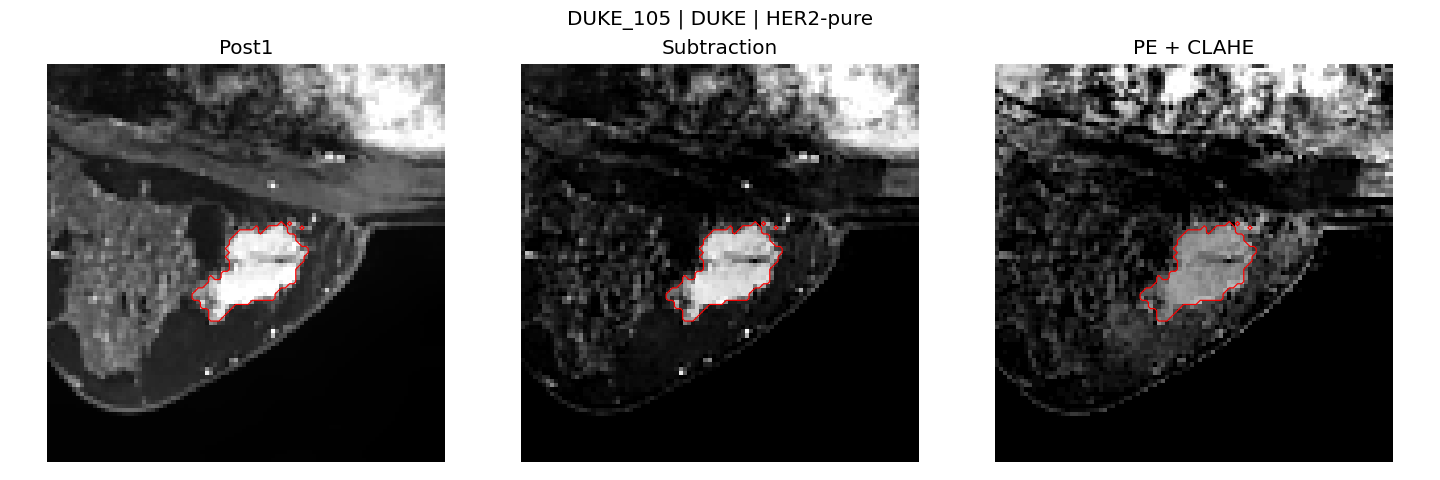

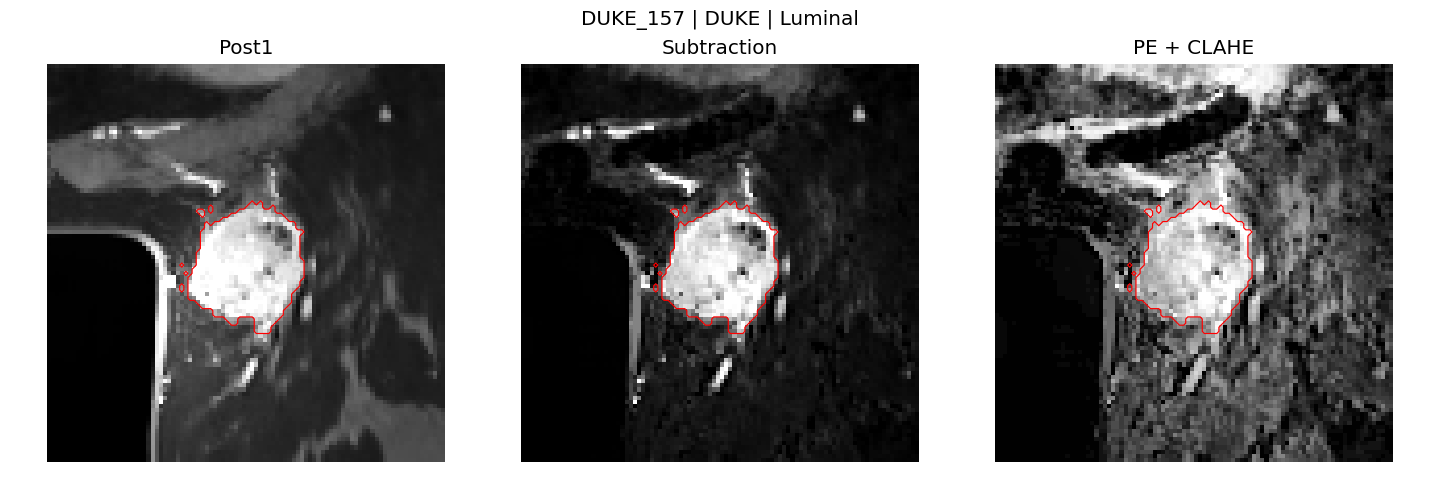

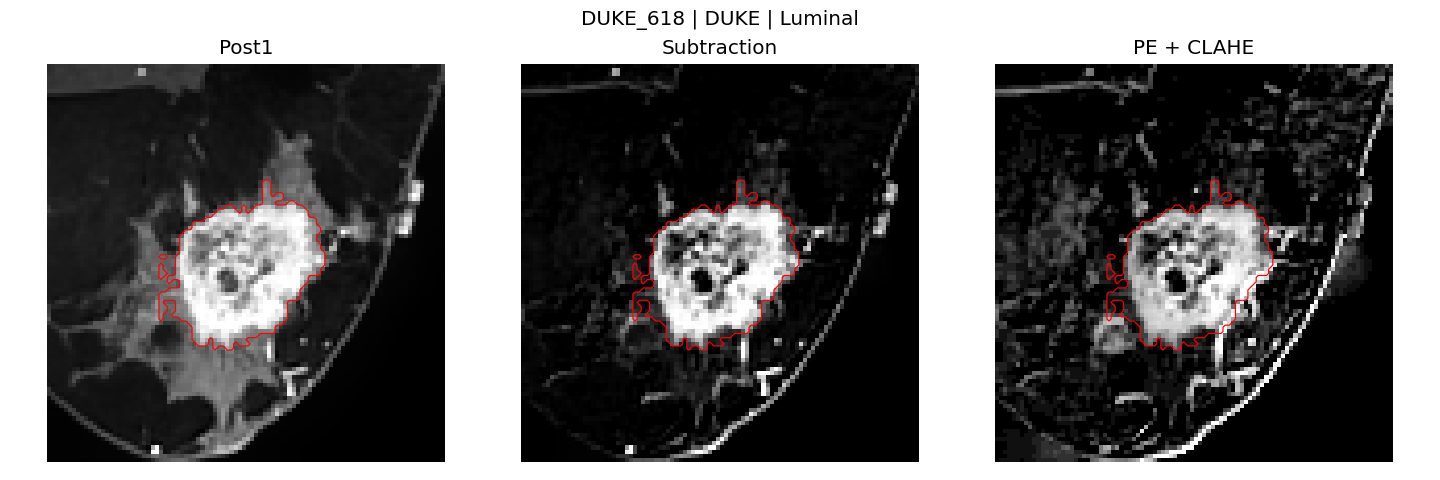

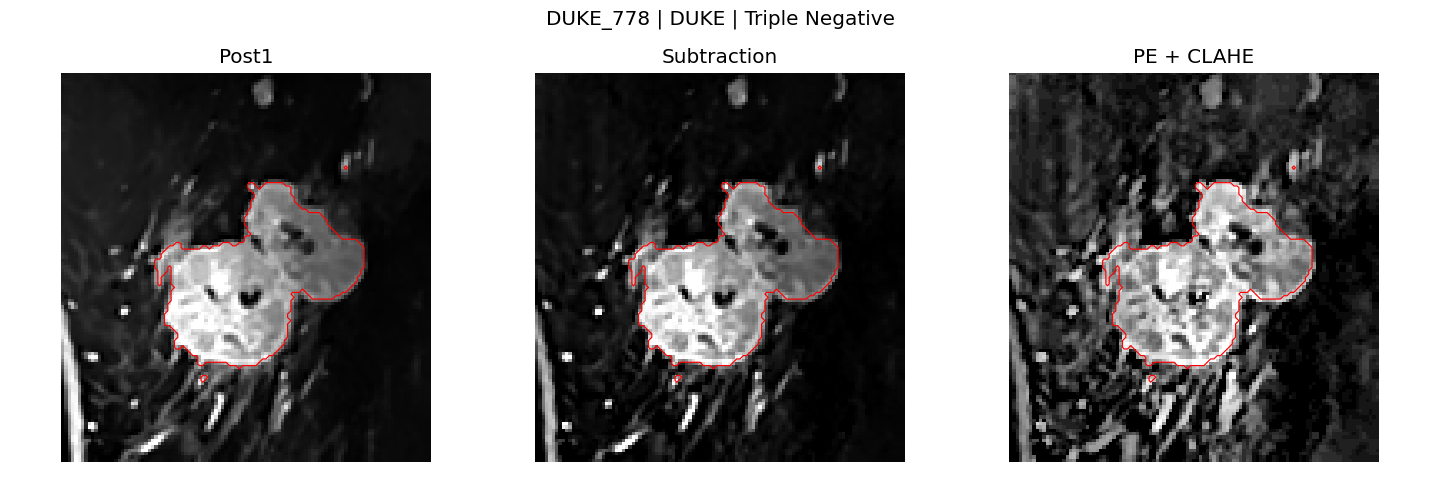

In [6]:
import json
from IPython.display import display, Image
REPORTS = DATA / 'tv2_step3' / 'reports'
inventory = json.loads((REPORTS / 'inventory.json').read_text())
print('TV1 NPZ:', inventory['expected'] - len(inventory['missing_tv1']), '/', inventory['expected'])
print('Step 2 VOI:', inventory['available_voi'], '/', inventory['expected'])
print('VOI còn thiếu (tối đa 10 ID đầu):', inventory['missing_voi'][:10])
print(json.dumps(json.loads((REPORTS / 'qc_summary.json').read_text()), indent=2, ensure_ascii=False))
print('Báo cáo và hình đã lưu trên Drive:', REPORTS)
for figure in sorted((REPORTS / 'figures').glob('*.png'))[:4]:
    display(Image(filename=str(figure), width=850))
